# 04, Robustness and the review band

How sure are the results, and what if borderline cases go to a person? Everything here uses the training split (out-of-fold) except section 1, which reuses the logged test-set confusion matrix without scoring the test set again.

Rule throughout: isotonic-calibrated P(bad), reject if P(bad) >= 1/6.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

sys.path.append('..')
from src.config import RANDOM_STATE
from src.data.load import load_dataset
from src.evaluation.calibration import calibrated
from src.evaluation.cost_analysis import expected_cost_at, review_band_table, theoretical_threshold
from src.evaluation.cv_evaluate import oof_predict
from src.evaluation.robustness import (
    bootstrap_cost_from_counts, bootstrap_saving_vs_reject_all,
    paired_bootstrap_cost_diff, repeated_cv_cost,
)
from src.evaluation.splits import get_cv_and_holdout
from src.models.pipelines import build_candidates

FIG_DIR = Path('../experiments/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)

df = load_dataset()
X_train, X_test, y_train, y_test, skf = get_cv_and_holdout(df)
T = theoretical_threshold()
print(f'seed={RANDOM_STATE}, train={X_train.shape}, threshold={T:.4f}')

seed=42, train=(800, 20), threshold=0.1667


## 1. Uncertainty around the test-set result

Confusion matrix of the one logged test-set run (RandomForest, isotonic, 1/6). 10,000 bootstrap resamples of the 200 applicants.

In [2]:
TEST_CM = [[61, 79], [5, 55]]
test_ci = bootstrap_cost_from_counts(TEST_CM)
saving = bootstrap_saving_vs_reject_all(TEST_CM)
print(f"test cost {test_ci['cost']:.3f}, 95% CI [{test_ci['ci_low']:.3f}, {test_ci['ci_high']:.3f}]")
print(f"model minus reject-everyone {saving['diff']:.3f}, 95% CI [{saving['ci_low']:.3f}, {saving['ci_high']:.3f}], "
      f"model cheaper in {saving['share_model_cheaper']:.1%} of resamples")

test cost 0.520, 95% CI [0.410, 0.645]
model minus reject-everyone -0.180, 95% CI [-0.300, -0.040], model cheaper in 99.3% of resamples


## 2. Out-of-fold cost per model, with intervals

In [3]:
models = build_candidates(y_train)
oof = {name: oof_predict(calibrated(p, 'isotonic'), X_train, y_train, skf) for name, p in models.items()}
rows = []
for name, p in oof.items():
    cm = confusion_matrix(y_train, (p >= T).astype(int), labels=[0, 1])
    ci = bootstrap_cost_from_counts(cm)
    rows.append({'model': name, 'oof_cost': ci['cost'], 'ci_low': ci['ci_low'], 'ci_high': ci['ci_high']})
pd.DataFrame(rows)

,model,oof_cost,ci_low,ci_high
0,LogReg,0.539,0.479,0.603
1,RandomForest,0.505,0.450,0.561
2,XGBoost,0.522,0.464,0.583


### Paired differences (same applicants in every resample)

In [4]:
pairs = [('RandomForest', 'XGBoost'), ('RandomForest', 'LogReg'), ('XGBoost', 'LogReg')]
pd.DataFrame([
    {'a': a, 'b': b, **paired_bootstrap_cost_diff(y_train, oof[a], oof[b], T)}
    for a, b in pairs
])

,a,b,diff,ci_low,ci_high,share_a_cheaper
0,RandomForest,XGBoost,-0.017,-0.064,0.027,0.764
1,RandomForest,LogReg,-0.034,-0.084,0.016,0.903
2,XGBoost,LogReg,-0.016,-0.069,0.036,0.717


## 3. Repeated cross-validation (5 folds x 5 repeats)

In [5]:
rcv = {name: repeated_cv_cost(calibrated(p, 'isotonic'), X_train, y_train, T) for name, p in models.items()}
pd.DataFrame({name: {'mean': c.mean(), 'std': c.std(), 'min': c.min(), 'max': c.max()} for name, c in rcv.items()}).T

,mean,std,min,max
LogReg,0.531,0.059,0.375,0.650
RandomForest,0.513,0.048,0.431,0.606
XGBoost,0.536,0.049,0.419,0.637


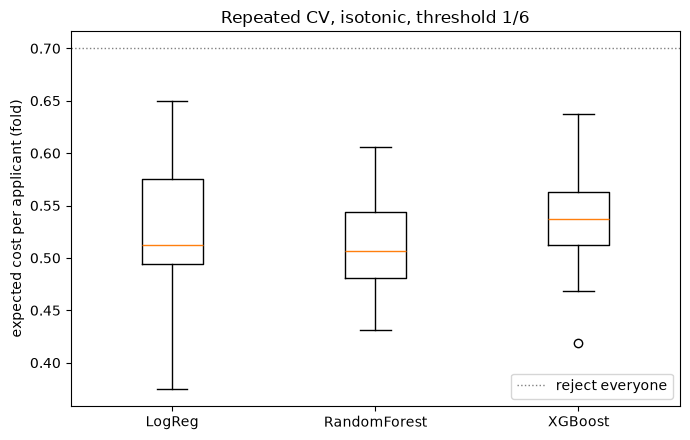

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(list(rcv.values()), tick_labels=list(rcv.keys()))
ax.axhline(0.7, color='grey', ls=':', lw=1, label='reject everyone')
ax.set_ylabel('expected cost per applicant (fold)')
ax.set_title('Repeated CV, isotonic, threshold 1/6')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'repeated_cv_cost.png', dpi=150)
plt.show()

## 4. Review band (RandomForest, isotonic, out-of-fold)

Approve below `low`, reject at or above `high`, send the rest to a person. The reviewer's decisions are not modelled; the table shows how many cases go to review, how risky they are, and the cost of the decisions that stay automatic.

In [7]:
BANDS = [(T, T), (0.12, 0.22), (0.10, 0.30), (0.08, 0.40)]
band = review_band_table(y_train, oof['RandomForest'], BANDS)
band

,low,high,share_approved,share_rejected,share_review,bad_rate_review,bad_rate_approved,cost_per_auto_decision
0,0.167,0.167,0.315,0.685,0.000,NaN,0.063,0.505
1,0.120,0.220,0.237,0.611,0.151,0.174,0.047,0.477
2,0.100,0.300,0.200,0.456,0.344,0.175,0.044,0.410
3,0.080,0.400,0.161,0.279,0.560,0.237,0.039,0.338


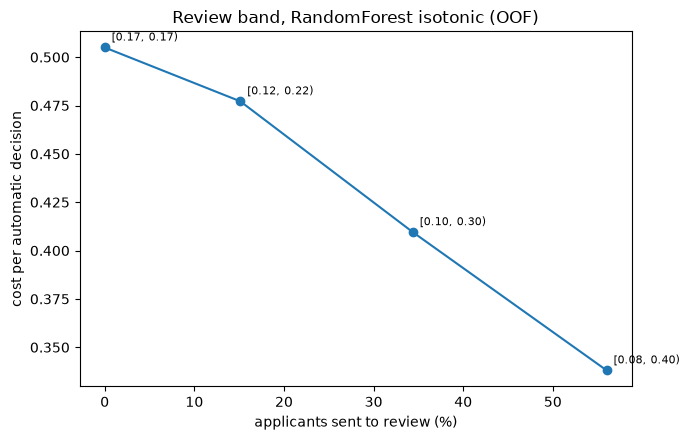

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(band['share_review'] * 100, band['cost_per_auto_decision'], 'o-')
for _, r in band.iterrows():
    ax.annotate(f"[{r['low']:.2f}, {r['high']:.2f})", (r['share_review'] * 100, r['cost_per_auto_decision']),
                textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.set_xlabel('applicants sent to review (%)')
ax.set_ylabel('cost per automatic decision')
ax.set_title('Review band, RandomForest isotonic (OOF)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'review_band.png', dpi=150)
plt.show()